In [1]:
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mlt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import numpy as np
from sklearn.model_selection import learning_curve
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn import datasets
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix


In [2]:
data_vin= datasets.load_wine()

In [3]:
df_vin=pd.DataFrame(data_vin['data'],columns=data_vin['feature_names'])
df_vin

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0


In [4]:
X=df_vin
Y=data_vin['target']

In [5]:
x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.25,random_state=100)

In [6]:
model=SVC()

In [7]:
model.fit(x_train,y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [8]:
prediction=model.predict(x_test)

In [9]:
prediction

array([1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0,
       1, 1, 2, 0, 1, 1, 1, 1, 1, 2, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 2, 1,
       0])

In [10]:
y_test

array([1, 2, 0, 1, 2, 2, 1, 1, 1, 1, 2, 1, 2, 2, 2, 0, 2, 0, 1, 0, 2, 0,
       1, 1, 0, 0, 1, 1, 1, 2, 2, 1, 0, 1, 2, 2, 1, 1, 2, 2, 0, 2, 2, 2,
       0])

In [11]:
model.score(x_train,y_train)

0.7293233082706767

In [12]:
print(confusion_matrix(y_test,prediction))

[[ 9  0  1]
 [ 2 14  1]
 [ 1 16  1]]


In [13]:
grid_param={'C':[0.1,1,5,10,15,20,30,40,50,100,1000,10000,100000],
             'gamma':[0.0000001,0.000001,0.00001,0.0001,0.001,0.01,0.1,1]

}

In [14]:
grid=GridSearchCV(SVC(),grid_param,verbose=10)

In [15]:
grid.fit(x_train,y_train)

Fitting 5 folds for each of 104 candidates, totalling 520 fits
[CV 1/5; 1/104] START C=0.1, gamma=1e-07........................................
[CV 1/5; 1/104] END .........C=0.1, gamma=1e-07;, score=0.407 total time=   0.0s
[CV 2/5; 1/104] START C=0.1, gamma=1e-07........................................
[CV 2/5; 1/104] END .........C=0.1, gamma=1e-07;, score=0.407 total time=   0.0s
[CV 3/5; 1/104] START C=0.1, gamma=1e-07........................................
[CV 3/5; 1/104] END .........C=0.1, gamma=1e-07;, score=0.407 total time=   0.0s
[CV 4/5; 1/104] START C=0.1, gamma=1e-07........................................
[CV 4/5; 1/104] END .........C=0.1, gamma=1e-07;, score=0.385 total time=   0.0s
[CV 5/5; 1/104] START C=0.1, gamma=1e-07........................................
[CV 5/5; 1/104] END .........C=0.1, gamma=1e-07;, score=0.423 total time=   0.0s
[CV 1/5; 2/104] START C=0.1, gamma=1e-06........................................
[CV 1/5; 2/104] END .........C=0.1, gamma=1e-0

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 1, ...], 'gamma': [1e-07, 1e-06, ...]}"
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These s

In [16]:
grid.best_score_

np.float64(0.9552706552706554)

In [17]:
grid.best_params_

{'C': 100000, 'gamma': 1e-06}

In [18]:
grid_model=grid.best_estimator_

grid_predict=grid_model.predict(x_test)
grid_model.score(x_train,y_train)

1.0

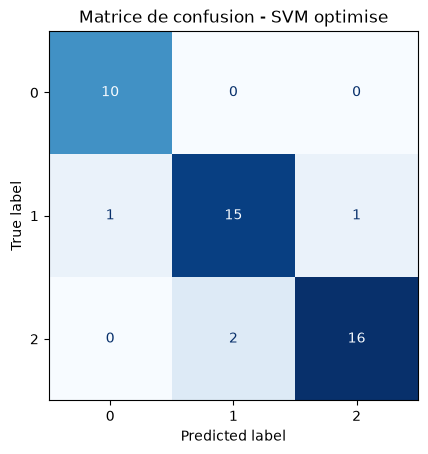

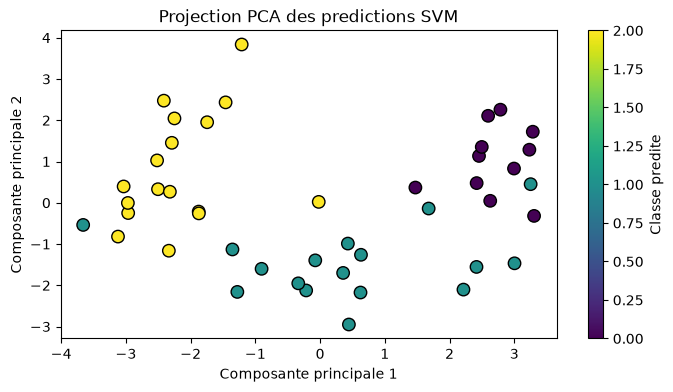

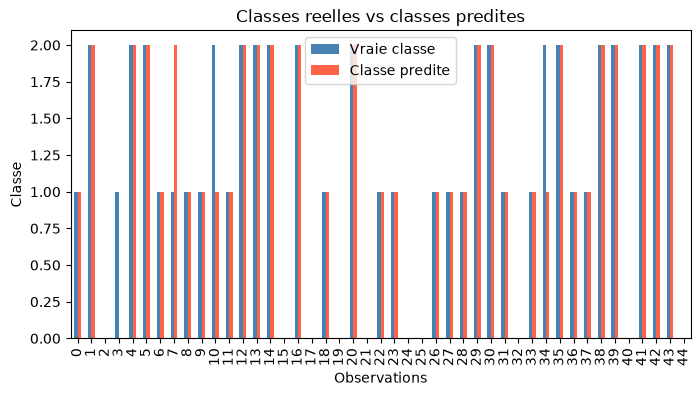

Score sur les donnees de test : 0.9111111111111111


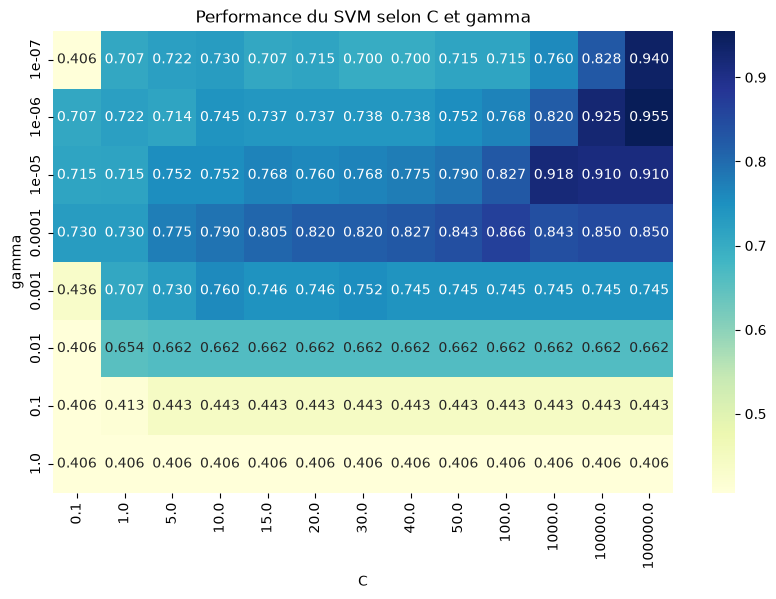

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Matrice de confusion du meilleur modele
ConfusionMatrixDisplay.from_predictions(
    y_test,
    grid_predict,
    cmap="Blues",
    colorbar=False
)
plt.title("Matrice de confusion - SVM optimise")
plt.show()

# Projection PCA des observations test
X_test_scaled = StandardScaler().fit_transform(x_test)
X_test_pca = PCA(n_components=2).fit_transform(X_test_scaled)

plt.figure(figsize=(8, 4))
scatter = plt.scatter(
    X_test_pca[:, 0],
    X_test_pca[:, 1],
    c=grid_predict,
    cmap="viridis",
    s=80,
    edgecolor="black"
)
plt.xlabel("Composante principale 1")
plt.ylabel("Composante principale 2")
plt.title("Projection PCA des predictions SVM")
plt.colorbar(scatter, label="Classe predite")
plt.show()

# Comparaison des classes reelles et predites
comparison = pd.DataFrame({
    "Vraie classe": y_test,
    "Classe predite": grid_predict
})

comparison.plot(
    kind="bar",
    figsize=(8, 4),
    color=["steelblue", "tomato"]
)
plt.title("Classes reelles vs classes predites")
plt.xlabel("Observations")
plt.ylabel("Classe")
plt.legend()
plt.show()

print("Score sur les donnees de test :", accuracy_score(y_test, grid_predict))

# Performances obtenues pour les hyperparametres C et gamma
results = pd.DataFrame(grid.cv_results_)
heatmap_data = results.pivot_table(
    index="param_gamma",
    columns="param_C",
    values="mean_test_score"
)

plt.figure(figsize=(10, 6))
sns.heatmap(heatmap_data, annot=True, cmap="YlGnBu", fmt=".3f")
plt.title("Performance du SVM selon C et gamma")
plt.xlabel("C")
plt.ylabel("gamma")
plt.show()

description pour le portifilio:
j'ai développé un modèle de Machine Learning capable de classer des vins en trois catégories à partir de leurs caractéristiques chimiques, comme le taux d'alcool, l'acidité, les phénols et l'intensité de la couleur.
Les graphiques permettent d'analyser les performances du modèle : matrice de confusion, projection PCA des catégories de vins, comparaison entre les classes réelles et prédites, ainsi que l'influence des hyperparamètres.
Le modèle atteint une précision de 91,1 % sur les données de test, ce qui montre qu'il reconnaît efficacement les catégories de vins à partir de leur composition chimique.